# Dataset Understanding

## 1. Reading pdf paths

In [1]:
from pathlib import Path
from collections import Counter

BASE_DIR = Path("../data/raw")

category_stats = []

total_pdfs = 0
total_other_Files = 0

for category_path in sorted(BASE_DIR.iterdir()):
    if not category_path.is_dir():
        continue
    
    files = [f for f in category_path.iterdir() if f.is_file()]
    pdf_files = [
        f for f in files 
        if f.suffix.lower() == ".pdf"
    ]
    
    other_files = len(files) - len(pdf_files)
    
    total_pdfs += len(pdf_files)

    total_other_Files += other_files
    
    category_stats.append({
        "Category" : category_path.name,
        "Total Files" : len(files),
        "PDF Files" : len(pdf_files),
        "Other Files" : other_files
    })
# Display Results
for state in category_stats:
    print(
        f"{state["Category"]:<45}"
        f"PDFs : {state["PDF Files"]:>4} | "
        f"Other Files : {state["Other Files"]:>3}"
    )

    
print("\n" + "=" *65)
print(f"Total Categories : {len(category_stats)}")
print(f"Total PDF Files : {total_pdfs}")
print(f"Total Other Files : {total_other_Files}")

cancer-clinical-studies                      PDFs :   52 | Other Files :   0
cancer-clinical-trials                       PDFs :   57 | Other Files :   0
cancer-meta-analyses                         PDFs :   17 | Other Files :   0
cancer-review-papers                         PDFs :   40 | Other Files :   0
drug-resistance-cancer-cases                 PDFs :   37 | Other Files :   0
molecular-biology-cancer-mechanisms          PDFs :   56 | Other Files :   0
targeted-therapy-cancer-cases                PDFs :   55 | Other Files :   0

Total Categories : 7
Total PDF Files : 314
Total Other Files : 0


## 2. Visualize Documents Distribution

,Category,Total Files,PDF Files,Other Files
0,cancer-clinical-studies,52,52,0
1,cancer-clinical-trials,57,57,0
2,cancer-meta-analyses,17,17,0
3,cancer-review-papers,40,40,0
4,drug-resistance-cancer-cases,37,37,0
5,molecular-biology-cancer-mechanisms,56,56,0
6,targeted-therapy-cancer-cases,55,55,0


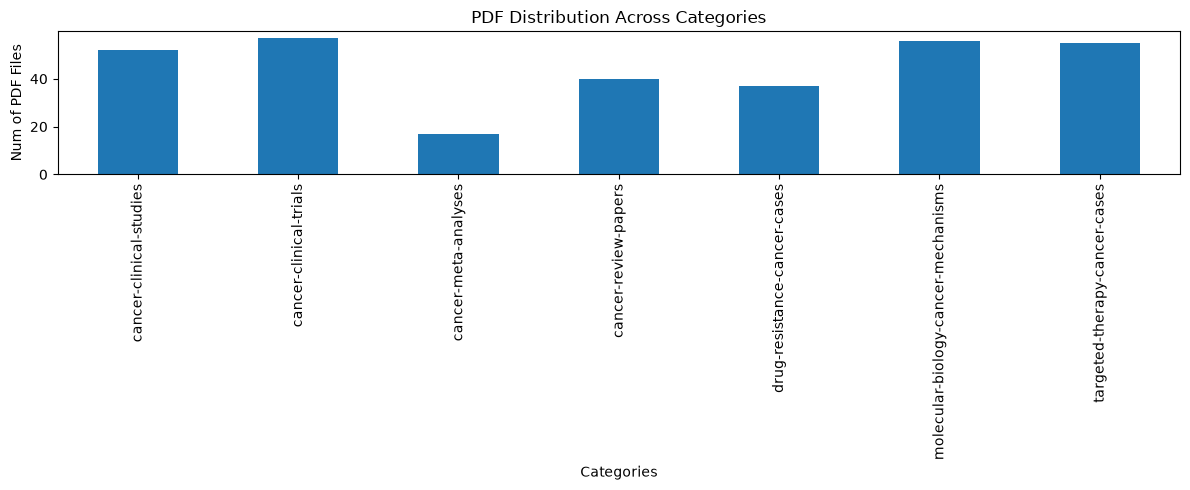

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(category_stats)
display(df)

df.plot(
    x="Category",
    y="PDF Files",
    kind="bar",
    legend=False,
    figsize=(12, 5)
)
plt.title("PDF Distribution Across Categories")
plt.xlabel("Categories")
plt.ylabel("Num of PDF Files")
plt.tight_layout()
plt.show()

# Parsing

## 1. PyMuPDF Technology

In [3]:
import fitz

# select one PDF 
pdf_path = next(BASE_DIR.rglob("*.pdf"))

# Open PDF 
doc = fitz.open(pdf_path)

print(f"pdf name : {pdf_path.name}")
print("=" * 65)
print(f"number of pages : {doc.page_count}")
print("=" * 65)
print(f"Meta Data : {doc.metadata}")


pdf name : A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG Improves Oral Squamous Cell Carcinoma Detection in Humans.pdf
number of pages : 11
Meta Data : {'format': 'PDF 1.4', 'title': 'A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG Improves Oral Squamous Cell Carcinoma Detection in Humans', 'author': 'Jingbo Wang ', 'subject': 'Annals of Surgical Oncology, https://doi.org/10.1245/s10434-022-12532-x', 'keywords': '', 'creator': 'Springer', 'producer': '', 'creationDate': "D:20220925130137+05'30'", 'modDate': "D:20221123105857+05'30'", 'trapped': '', 'encryption': None}


d:\Projects\OncoLens-GenAI\.venv\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [4]:
# Get First Page
page = doc[0]

# Extract Text
page_text = page.get_text()

print(f"Page Number : {page.number + 1}")
print(f"Extracted Characters : {len(page_text)}")
print("=" * 65)
print(page_text[:3000])

Page Number : 1
Extracted Characters : 3478
ORIGINAL ARTICLE – TRANSLATIONAL RESEARCH
A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG
Improves Oral Squamous Cell Carcinoma Detection in Humans
Jingbo Wang, MD1
, Siyi Li, MD2, Kun Wang, PhD3, Ling Zhu, MD1, Lin Yang, MD1,
Yunjing Zhu, MD1, Zhen Zhang, MD2, Longwei Hu, MD2, Yuan Yuan, MD1, Qi Fan, MD1,
Jiliang Ren, MD1, Gongxin Yang, MD1, Weilong Ding, BS1, Xiaoyu Zhou, BS4, Junqi Cui, BS5,
Chunye Zhang, MD5, Ying Yuan, MD1, Ruimin Huang, PhD4, Jie Tian, PhD3, and
Xiaofeng Tao, MD1
1Department of Radiology, Ninth People’s Hospital, School of Medicine, Shanghai Jiao Tong University, Shanghai, China;
2Department of Oral and Maxillofacial-Head and Neck Oncology, Ninth People’s Hospital, School of Medicine, Shanghai
Jiao Tong University, Shanghai, China; 3CAS Key Laboratory of Molecular Imaging, Beijing Key Laboratory of Molecular
Imaging, The State Key Laboratory of Management and Control for Complex Systems, Institute of Automation, Chi

In [5]:
for page in doc:
    text = page.get_text()

    print(f"\n{'=' * 30}")
    print(f"Page Number: {page.number + 1}")
    print(f"Characters: {len(text)}")
    print(f"{'=' * 30}")

    print(text[:1000])


Page Number: 1
Characters: 3478
ORIGINAL ARTICLE – TRANSLATIONAL RESEARCH
A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG
Improves Oral Squamous Cell Carcinoma Detection in Humans
Jingbo Wang, MD1
, Siyi Li, MD2, Kun Wang, PhD3, Ling Zhu, MD1, Lin Yang, MD1,
Yunjing Zhu, MD1, Zhen Zhang, MD2, Longwei Hu, MD2, Yuan Yuan, MD1, Qi Fan, MD1,
Jiliang Ren, MD1, Gongxin Yang, MD1, Weilong Ding, BS1, Xiaoyu Zhou, BS4, Junqi Cui, BS5,
Chunye Zhang, MD5, Ying Yuan, MD1, Ruimin Huang, PhD4, Jie Tian, PhD3, and
Xiaofeng Tao, MD1
1Department of Radiology, Ninth People’s Hospital, School of Medicine, Shanghai Jiao Tong University, Shanghai, China;
2Department of Oral and Maxillofacial-Head and Neck Oncology, Ninth People’s Hospital, School of Medicine, Shanghai
Jiao Tong University, Shanghai, China; 3CAS Key Laboratory of Molecular Imaging, Beijing Key Laboratory of Molecular
Imaging, The State Key Laboratory of Management and Control for Complex Systems, Institute of Automation, Chinese
Academ

In [6]:
page = doc[1]  # Page 2

blocks = page.get_text("blocks")

print(f"Number of Blocks: {len(blocks)}")

for i, block in enumerate(blocks):
    x0, y0, x1, y1, text, *_ = block

    print(f"\nBlock {i + 1}")
    print(f"Position: ({x0:.1f}, {y0:.1f}, {x1:.1f}, {y1:.1f})")
    print(f"Text: {text[:300]}")

Number of Blocks: 16

Block 1
Position: (51.0, 54.2, 289.1, 218.1)
Text: evaluated by visual inspection.2,3 However, translation of
information from preoperative imaging into the actual sit-
uation in the patient during surgery is challenging, and
macroscopic evaluation of a tumor in the oral cavity by
palpation
during
surgery
is
difﬁcult
and
inaccurate.
Moreover, the pr

Block 2
Position: (51.0, 220.6, 289.1, 255.4)
Text: The merging of targeted probes with clinical user-
friendly imaging technologies provides a powerful and
easy tool for the early and precise detection of cancer.6–8


Block 3
Position: (51.0, 257.9, 289.2, 454.6)
Text: Near-infrared (NIR) ﬂuorescence-guided surgery is a
promising technique for superﬁcial head and neck lesions
using tumor-targeting ﬂuorescent agents (e.g., panitu-
mumab-IRDye800CW, cetuximab-IRDye800CW).9,10 For
local
small-distance
metastases,
extracellular
matrix
(ECM) may prevent the penetration

Block 4
Position: (51.0, 457.2, 289.1, 566.7)
Text: 

In [7]:
page = doc[1]

page_dict = page.get_text("dict")

for block_num, block in enumerate(page_dict["blocks"]):

    if block["type"] != 0:
        continue

    print(f"\nBlock {block_num + 1}")

    for line in block["lines"]:

        line_text = ""

        for span in line["spans"]:
            line_text += span["text"]

        print(line_text)
    


Block 1
evaluated by visual inspection.2,3 However, translation of
information from preoperative imaging into the actual sit-
uation in the patient during surgery is challenging, and
macroscopic evaluation of a tumor in the oral cavity by
palpation
during
surgery
is
difﬁcult
and
inaccurate.
Moreover, the precursor lesions, such as oral leukoplakia
and submucous ﬁbrosis, can subsequently progress to
cancers,4 whereas the ability to detect malignant transfor-
mation early is limited, and preoperative biopsies may
suffer from sample error.5 Therefore, it is necessary to
develop supplementary methods for precise detection of
early malignancy and delineation of mucosal extension of
the tumor.

Block 2
The merging of targeted probes with clinical user-
friendly imaging technologies provides a powerful and
easy tool for the early and precise detection of cancer.6–8

Block 3
Near-infrared (NIR) ﬂuorescence-guided surgery is a
promising technique for superﬁcial head and neck lesions
using tumo

In [8]:
page = doc[1]

page_dict = page.get_text("dict")

for block_num, block in enumerate(page_dict["blocks"]):

    if block["type"] != 0:
        continue

    for line in block["lines"]:

        for span in line["spans"]:

            print({
                "text": span["text"][:80],
                "font": span["font"],
                "size": span["size"],
                "flags": span["flags"],
                "bbox": span["bbox"]
            })

{'text': 'evaluated', 'font': 'AdvPTimes', 'size': 9.962599754333496, 'flags': 4, 'bbox': (51.02360153198242, 58.656837463378906, 89.4842300415039, 68.61943817138672)}
{'text': ' ', 'font': 'AdvPTimes', 'size': 9.962599754333496, 'flags': 4, 'bbox': (89.4842300415039, 58.656837463378906, 93.31584930419922, 68.61943817138672)}
{'text': 'by', 'font': 'AdvPTimes', 'size': 9.962599754333496, 'flags': 4, 'bbox': (93.31584930419922, 58.656837463378906, 103.27845001220703, 68.61943817138672)}
{'text': ' ', 'font': 'AdvPTimes', 'size': 9.962599754333496, 'flags': 4, 'bbox': (103.27845001220703, 58.656837463378906, 107.14891815185547, 68.61943817138672)}
{'text': 'visual', 'font': 'AdvPTimes', 'size': 9.962599754333496, 'flags': 4, 'bbox': (107.14891815185547, 58.656837463378906, 130.99937438964844, 68.61943817138672)}
{'text': ' ', 'font': 'AdvPTimes', 'size': 9.962599754333496, 'flags': 4, 'bbox': (130.99937438964844, 58.656837463378906, 134.87184143066406, 68.61943817138672)}
{'text': 'inspe

In [9]:
from collections import Counter

font_stats = Counter()

for block in page_dict["blocks"]:
    if block["type"] != 0:
        continue

    for line in block["lines"]:
        for span in line["spans"]:
            key = (
                span["font"],
                round(span["size"], 1),
                span["flags"]
            )

            font_stats[key] += len(span["text"])

for (font, size, flags), chars in font_stats.most_common():
    print(
        f"Font: {font:<25} "
        f"Size: {size:<5} "
        f"Flags: {flags:<3} "
        f"Characters: {chars}"
    )

Font: AdvPTimes                 Size: 10.0  Flags: 4   Characters: 4595
Font: AdvPTimesI                Size: 10.0  Flags: 4   Characters: 127
Font: AdvPTimes                 Size: 7.0   Flags: 5   Characters: 27
Font: AdvPTimes                 Size: 8.5   Flags: 4   Characters: 17
Font: AdvPTimesB                Size: 10.0  Flags: 4   Characters: 7
Font: AdvPTimes                 Size: 10.0  Flags: 5   Characters: 6
Font: AdvPSMP13                 Size: 10.0  Flags: 4   Characters: 4
Font: AdvTir_symb               Size: 10.0  Flags: 4   Characters: 2
Font: AdvTir_symb               Size: 7.0   Flags: 5   Characters: 1


## 2. PDFPlumber

In [10]:
import pdfplumber

# Select the same pdf
pdf_path = next(BASE_DIR.rglob("*.pdf"))

# Open PDF
pdf = pdfplumber.open(pdf_path)

print(f"PDF Name : {pdf_path.name}")
print("=" * 65)
print(f"number of pages : {len(pdf.pages)}")
print("=" * 65)
print(f"Meta Data : {pdf.metadata}")

PDF Name : A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG Improves Oral Squamous Cell Carcinoma Detection in Humans.pdf
number of pages : 11
Meta Data : {'Author': 'Jingbo Wang ', 'CreationDate': "D:20220925130137+05'30'", 'Creator': 'Springer', 'CrossMarkDomains[1]': 'springer.com', 'CrossMarkDomains[2]': 'springerlink.com', 'CrossmarkDomainExclusive': 'true', 'CrossmarkMajorVersionDate': '2010-04-23', 'ModDate': "D:20221123105857+05'30'", 'Subject': 'Annals of Surgical Oncology, https://doi.org/10.1245/s10434-022-12532-x', 'Title': 'A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG Improves Oral Squamous Cell Carcinoma Detection in Humans', 'doi': '10.1245/s10434-022-12532-x', 'robots': 'noindex'}


In [11]:
# Get First Page
page = pdf.pages[0]

# Extract Text
page_text = page.extract_text()

print(f"Page Number : {page.page_number}")
print(f"Extracted Characters : {len(page_text) if page_text else 0}")
print("=" * 65)
print(page_text[:3000] if page_text else "No text Extracted")

Page Number : 1
Extracted Characters : 3353
AnnSurgOncol(2023)30:641–651
https://doi.org/10.1245/s10434-022-12532-x
ORIGINAL ARTICLE – TRANSLATIONAL RESEARCH
A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG
Improves Oral Squamous Cell Carcinoma Detection in Humans
Jingbo Wang, MD1 , Siyi Li, MD2, Kun Wang, PhD3, Ling Zhu, MD1, Lin Yang, MD1,
Yunjing Zhu, MD1, Zhen Zhang, MD2, Longwei Hu, MD2, Yuan Yuan, MD1, Qi Fan, MD1,
Jiliang Ren, MD1, Gongxin Yang, MD1, Weilong Ding, BS1, Xiaoyu Zhou, BS4, Junqi Cui, BS5,
Chunye Zhang, MD5, Ying Yuan, MD1, Ruimin Huang, PhD4, Jie Tian, PhD3, and
Xiaofeng Tao, MD1
1DepartmentofRadiology,NinthPeople’sHospital,SchoolofMedicine,ShanghaiJiaoTongUniversity,Shanghai,China;
2DepartmentofOralandMaxillofacial-HeadandNeckOncology,NinthPeople’sHospital,SchoolofMedicine,Shanghai
JiaoTongUniversity,Shanghai,China;3CASKeyLaboratoryofMolecularImaging,BeijingKeyLaboratoryofMolecular
Imaging,TheState Key Laboratory ofManagement andControlfor ComplexSystems, Insti

In [12]:
for page in pdf.pages:
    text = page.extract_text()

    print(f"\n{'=' * 30}")
    print(f"Page Number: {page.page_number}")
    print(f"Characters: {len(text) if text else 0}")
    print(f"{'=' * 30}")

    print(text[:1000] if text else "No text extracted")


Page Number: 1
Characters: 3353
AnnSurgOncol(2023)30:641–651
https://doi.org/10.1245/s10434-022-12532-x
ORIGINAL ARTICLE – TRANSLATIONAL RESEARCH
A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG
Improves Oral Squamous Cell Carcinoma Detection in Humans
Jingbo Wang, MD1 , Siyi Li, MD2, Kun Wang, PhD3, Ling Zhu, MD1, Lin Yang, MD1,
Yunjing Zhu, MD1, Zhen Zhang, MD2, Longwei Hu, MD2, Yuan Yuan, MD1, Qi Fan, MD1,
Jiliang Ren, MD1, Gongxin Yang, MD1, Weilong Ding, BS1, Xiaoyu Zhou, BS4, Junqi Cui, BS5,
Chunye Zhang, MD5, Ying Yuan, MD1, Ruimin Huang, PhD4, Jie Tian, PhD3, and
Xiaofeng Tao, MD1
1DepartmentofRadiology,NinthPeople’sHospital,SchoolofMedicine,ShanghaiJiaoTongUniversity,Shanghai,China;
2DepartmentofOralandMaxillofacial-HeadandNeckOncology,NinthPeople’sHospital,SchoolofMedicine,Shanghai
JiaoTongUniversity,Shanghai,China;3CASKeyLaboratoryofMolecularImaging,BeijingKeyLaboratoryofMolecular
Imaging,TheState Key Laboratory ofManagement andControlfor ComplexSystems, Instituteof Auto

In [13]:
page = pdf.pages[1]

words = page.extract_words()

print(f"Number of Words: {len(words)}")

for i, word in enumerate(words[:50]):

    print({
        "word": word["text"],
        "x0": round(word["x0"], 2),
        "top": round(word["top"], 2),
        "x1": round(word["x1"], 2),
        "bottom": round(word["bottom"], 2)
    })

Number of Words: 599
{'word': '642', 'x0': 51.02, 'top': 33.34, 'x1': 63.73, 'bottom': 41.81}
{'word': 'J.Wangetal.', 'x0': 495.67, 'top': 33.34, 'x1': 544.26, 'bottom': 41.81}
{'word': 'evaluated', 'x0': 51.02, 'top': 58.42, 'x1': 89.48, 'bottom': 68.38}
{'word': 'by', 'x0': 93.32, 'top': 58.42, 'x1': 103.28, 'bottom': 68.38}
{'word': 'visual', 'x0': 107.15, 'top': 58.42, 'x1': 131.0, 'bottom': 68.38}
{'word': 'inspection.2,3', 'x0': 134.87, 'top': 56.6, 'x1': 187.87, 'bottom': 68.38}
{'word': 'However,', 'x0': 191.74, 'top': 58.42, 'x1': 230.82, 'bottom': 68.38}
{'word': 'translation', 'x0': 234.65, 'top': 58.42, 'x1': 276.95, 'bottom': 68.38}
{'word': 'of', 'x0': 280.8, 'top': 58.42, 'x1': 289.1, 'bottom': 68.38}
{'word': 'METHODS', 'x0': 306.14, 'top': 58.3, 'x1': 357.15, 'bottom': 68.26}
{'word': 'information', 'x0': 51.02, 'top': 70.89, 'x1': 98.31, 'bottom': 80.85}
{'word': 'from', 'x0': 101.71, 'top': 70.89, 'x1': 121.1, 'bottom': 80.85}
{'word': 'preoperative', 'x0': 124.55, '

In [14]:
page = pdf.pages[1]

print(f"Number of Characters: {len(page.chars)}")

for char in page.chars[:30]:
    print({
        "text": char["text"],
        "font": char["fontname"],
        "size": round(char["size"], 2),
        "x0": round(char["x0"], 2),
        "top": round(char["top"], 2),
        "x1": round(char["x1"], 2),
        "bottom": round(char["bottom"], 2)
    })

Number of Characters: 4192
{'text': 'e', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 51.02, 'top': 58.42, 'x1': 55.48, 'bottom': 68.38}
{'text': 'v', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 55.48, 'top': 58.42, 'x1': 60.46, 'bottom': 68.38}
{'text': 'a', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 60.46, 'top': 58.42, 'x1': 64.91, 'bottom': 68.38}
{'text': 'l', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 64.91, 'top': 58.42, 'x1': 67.71, 'bottom': 68.38}
{'text': 'u', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 67.71, 'top': 58.42, 'x1': 72.69, 'bottom': 68.38}
{'text': 'a', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 72.69, 'top': 58.42, 'x1': 77.15, 'bottom': 68.38}
{'text': 't', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 77.15, 'top': 58.42, 'x1': 79.95, 'bottom': 68.38}
{'text': 'e', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 80.05, 'top': 58.42, 'x1': 84.5, 'bottom': 68.38}
{'text': 'd', 'font': 'NXNKKD+AdvPTimes', 'size': 9.96, 'x0': 84.5, 't

In [15]:

from collections import Counter

font_stats = Counter()

for char in page.chars:
    key = (
        char["fontname"],
        round(char["size"], 1)
    )

    font_stats[key] += 1

for (font, size), chars in font_stats.most_common():

    print(
        f"Font: {font:<35} "
        f"Size: {size:<5} "
        f"Characters: {chars}"
    )

Font: NXNKKD+AdvPTimes                    Size: 10.0  Characters: 4027
Font: UDOTRS+AdvPTimesI                   Size: 10.0  Characters: 112
Font: NXNKKD+AdvPTimes                    Size: 6.6   Characters: 27
Font: NXNKKD+AdvPTimes                    Size: 8.5   Characters: 14
Font: UHFJTH+AdvPTimesB                   Size: 10.0  Characters: 7
Font: ATJJCK+AdvPSMP13                    Size: 10.0  Characters: 3
Font: NGCDRG+AdvTir_symb                  Size: 10.0  Characters: 1
Font: NGCDRG+AdvTir_symb                  Size: 6.6   Characters: 1


## 3.PyPDF

In [16]:
from pypdf import PdfReader

# Select the same PDF
pdf_path = next(BASE_DIR.rglob("A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG*.pdf"))

# Open PDF
reader = PdfReader(pdf_path)

print(f"PDF Name: {pdf_path.name}")
print("=" * 65)
print(f"Number of Pages: {len(reader.pages)}")
print("=" * 65)
print(f"Metadata: {reader.metadata}")

PDF Name: A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG Improves Oral Squamous Cell Carcinoma Detection in Humans.pdf
Number of Pages: 11
Metadata: {'/Author': 'Jingbo Wang ', '/CreationDate': "D:20220925130137+05'30'", '/Creator': 'Springer', '/CrossMarkDomains[1]': 'springer.com', '/CrossMarkDomains[2]': 'springerlink.com', '/CrossmarkDomainExclusive': 'true', '/CrossmarkMajorVersionDate': '2010-04-23', '/ModDate': "D:20221123105857+05'30'", '/Subject': 'Annals of Surgical Oncology, https://doi.org/10.1245/s10434-022-12532-x', '/Title': 'A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG Improves Oral Squamous Cell Carcinoma Detection in Humans', '/doi': '10.1245/s10434-022-12532-x', '/robots': 'noindex'}


In [17]:
# Extract text from the first page
first_page_text = reader.pages[0].extract_text()

print(f"Page Number: 1")
print(f"Extracted Characters: {len(first_page_text)}")
print("=" * 65)
print(first_page_text)

Page Number: 1
Extracted Characters: 3478
ORIGINAL ARTICLE – TRANSLATIONAL RESEARCH
A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG
Improves Oral Squamous Cell Carcinoma Detection in Humans
Jingbo Wang, MD1 , Siyi Li, MD2, Kun Wang, PhD3, Ling Zhu, MD1, Lin Yang, MD1,
Yunjing Zhu, MD1, Zhen Zhang, MD2, Longwei Hu, MD2, Yuan Yuan, MD1,QiFan,MD1,
Jiliang Ren, MD1, Gongxin Yang, MD1, Weilong Ding, BS1, Xiaoyu Zhou, BS4, Junqi Cui, BS5,
Chunye Zhang, MD5, Ying Yuan, MD1, Ruimin Huang, PhD4, Jie Tian, PhD3, and
Xiaofeng Tao, MD1
1Department of Radiology, Ninth People’s Hospital, School of Medicine, Shanghai Jiao Tong University, Shanghai, China;
2Department of Oral and Maxillofacial-Head and Neck Oncology, Ninth People’s Hospital, School of Medicine, Shanghai
Jiao Tong University, Shanghai, China; 3CAS Key Laboratory of Molecular Imaging, Beijing Key Laboratory of Molecular
Imaging, The State Key Laboratory of Management and Control for Complex Systems, Institute of Automation, Chinese


In [18]:
for page_number, page in enumerate(reader.pages, start=1):
    text = page.extract_text() or ""

    print(f"Page Number: {page_number}")
    print(f"Extracted Characters: {len(text)}")
    print("=" * 65)
    print(text[:1000])
    print("\n")

Page Number: 1
Extracted Characters: 3478
ORIGINAL ARTICLE – TRANSLATIONAL RESEARCH
A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG
Improves Oral Squamous Cell Carcinoma Detection in Humans
Jingbo Wang, MD1 , Siyi Li, MD2, Kun Wang, PhD3, Ling Zhu, MD1, Lin Yang, MD1,
Yunjing Zhu, MD1, Zhen Zhang, MD2, Longwei Hu, MD2, Yuan Yuan, MD1,QiFan,MD1,
Jiliang Ren, MD1, Gongxin Yang, MD1, Weilong Ding, BS1, Xiaoyu Zhou, BS4, Junqi Cui, BS5,
Chunye Zhang, MD5, Ying Yuan, MD1, Ruimin Huang, PhD4, Jie Tian, PhD3, and
Xiaofeng Tao, MD1
1Department of Radiology, Ninth People’s Hospital, School of Medicine, Shanghai Jiao Tong University, Shanghai, China;
2Department of Oral and Maxillofacial-Head and Neck Oncology, Ninth People’s Hospital, School of Medicine, Shanghai
Jiao Tong University, Shanghai, China; 3CAS Key Laboratory of Molecular Imaging, Beijing Key Laboratory of Molecular
Imaging, The State Key Laboratory of Management and Control for Complex Systems, Institute of Automation, Chinese


## 4. Unstructured

In [19]:
from unstructured.partition.pdf import partition_pdf

# Select the same PDF
pdf_path = next(BASE_DIR.rglob("A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG*.pdf"))

# Extract PDF elements
elements = partition_pdf(
    filename=str(pdf_path),
    strategy="fast"
)

print(f"PDF Name: {pdf_path.name}")
print("=" * 65)
print(f"Number of Extracted Elements: {len(elements)}")
print("=" * 65)
print(f"Document Type: {type(elements).__name__}")

d:\Projects\OncoLens-GenAI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PDF Name: A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG Improves Oral Squamous Cell Carcinoma Detection in Humans.pdf
Number of Extracted Elements: 522
Document Type: list


In [20]:
from collections import Counter

element_types = Counter(
    element.category for element in elements
)

print("Extracted Element Types")
print("=" * 65)

for category, count in element_types.items():
    print(f"{category}: {count}")

print("=" * 65)
print(f"Total Elements: {sum(element_types.values())}")

Extracted Element Types
Header: 21
Title: 191
UncategorizedText: 161
NarrativeText: 119
ListItem: 30
Total Elements: 522


In [21]:
for i, element in enumerate(elements[:30], start=1):
    print(f"Element: {i}")
    print(f"Category: {element.category}")
    print(f"Text: {str(element)[:300]}")
    print("=" * 65)

Element: 1
Category: Header
Text: Ann Surg Oncol (2023) 30:641–651 https://doi.org/10.1245/s10434-022-12532-x
Element: 2
Category: Title
Text: ORIGINAL ARTICLE – TRANSLATIONAL RESEARCH
Element: 3
Category: UncategorizedText
Text: A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG Improves Oral Squamous Cell Carcinoma Detection in Humans
Element: 4
Category: UncategorizedText
Text: Jingbo Wang, MD1 Yunjing Zhu, MD1, Zhen Zhang, MD2, Longwei Hu, MD2, Yuan Yuan, MD1, Qi Fan, MD1, Jiliang Ren, MD1, Gongxin Yang, MD1, Weilong Ding, BS1, Xiaoyu Zhou, BS4, Junqi Cui, BS5, Chunye Zhang, MD5, Ying Yuan, MD1, Ruimin Huang, PhD4, Jie Tian, PhD3, and Xiaofeng Tao, MD1
Element: 5
Category: UncategorizedText
Text: , Siyi Li, MD2, Kun Wang, PhD3, Ling Zhu, MD1, Lin Yang, MD1,
Element: 6
Category: UncategorizedText
Text: 1Department of Radiology, Ninth People’s Hospital, School of Medicine, Shanghai Jiao Tong University, Shanghai, China; 2Department of Oral and Maxillofacial-Head and Neck Oncology, N

In [22]:
from collections import defaultdict

page_elements = defaultdict(Counter)

for element in elements:
    page_number = element.metadata.page_number
    category = element.category

    page_elements[page_number][category] += 1

for page_number in sorted(page_elements):
    print(f"\nPage: {page_number}")
    print("-" * 40)

    for category, count in page_elements[page_number].items():
        print(f"{category}: {count}")


Page: 1
----------------------------------------
Header: 1
Title: 9
UncategorizedText: 6
NarrativeText: 3

Page: 2
----------------------------------------
Header: 2
NarrativeText: 9
UncategorizedText: 1
Title: 8

Page: 3
----------------------------------------
Header: 2
NarrativeText: 8
Title: 5
UncategorizedText: 1

Page: 4
----------------------------------------
Header: 2
Title: 29
UncategorizedText: 12
NarrativeText: 20

Page: 5
----------------------------------------
Header: 2
Title: 42
NarrativeText: 16
UncategorizedText: 34
ListItem: 4

Page: 6
----------------------------------------
Header: 2
Title: 17
UncategorizedText: 24
NarrativeText: 10

Page: 7
----------------------------------------
Header: 2
Title: 23
NarrativeText: 15
UncategorizedText: 56

Page: 8
----------------------------------------
Header: 2
Title: 17
NarrativeText: 11
UncategorizedText: 24

Page: 9
----------------------------------------
Header: 2
Title: 30
NarrativeText: 17

Page: 10
-------------------

In [23]:
elements_hi_res = partition_pdf(
    filename=str(pdf_path),
    strategy="hi_res"
)

print(f"Total Elements: {len(elements_hi_res)}")
print("=" * 65)

element_types_hi_res = Counter(
    element.category for element in elements_hi_res
)

for category, count in element_types_hi_res.items():
    print(f"{category}: {count}")

Total Elements: 532
Header: 21
Image: 10
NarrativeText: 81
Title: 7
UncategorizedText: 370
FigureCaption: 9
Table: 1
ListItem: 33


In [24]:
for i, element in enumerate(elements_hi_res):
    if element.category in ["Table", "Image", "FigureCaption"]:
        print(f"Element: {i + 1}")
        print(f"Category: {element.category}")
        print(f"Page: {element.metadata.page_number}")
        print(f"Text: {str(element)[:700]}")

        if element.category == "Table":
            print(f"Table HTML: {element.metadata.text_as_html}")

        print("=" * 65)

Element: 2
Category: Image
Page: 1
Text: Annals of SURGICALONCOLOGY OFFICIAL JOURNAL OF THE SOCIETY OF SURGICAL ONCOLOGY
Element: 3
Category: Image
Page: 1
Text: ® “dae updates
Element: 64
Category: Image
Page: 4
Text: gargle1 min  gargle twice  gargle twice   1 min each   1 min each  cMBP-ICG  Mouthwash    pure water   3  5  topping agents  & pure water   Post-wash  pre-wash   6  Blank contol  4  2  wash twice  rinse1 min  wash twice   1 min each 
Element: 83
Category: FigureCaption
Page: 4
Text: min as a clearing solution (step 5), followed by cMBP-ICG administration of post-wash imaging (step 6). B Immediately after resection, tissue specimens, including margin samples, were imaged ex vivo in a vertical near-infrared imaging device Z2000 (DPM) following the same protocol described earlier. C Preoperative images were taken into consideration during the surgical procedure plan. Intraoperative back-table videos were transmitted in real time to the pathology gross room as frozen section

In [25]:
import time

# Benchmark Unstructured Fast
start = time.perf_counter()

elements_fast_test = partition_pdf(
    filename=str(pdf_path),
    strategy="fast"
)

fast_time = time.perf_counter() - start

# Benchmark Unstructured Hi-Res
start = time.perf_counter()

elements_hi_res_test = partition_pdf(
    filename=str(pdf_path),
    strategy="hi_res"
)

hi_res_time = time.perf_counter() - start

print(f"Fast Time: {fast_time:.2f} seconds")
print(f"Hi-Res Time: {hi_res_time:.2f} seconds")
print(f"Speed Ratio: {hi_res_time / fast_time:.2f}x")

Fast Time: 1.46 seconds
Hi-Res Time: 46.20 seconds
Speed Ratio: 31.58x


In [26]:
import pandas as pd

unstructured_results = pd.DataFrame([
    {
        "Strategy": "Fast",
        "Elements": 522,
        "Time (seconds)": 1.46,
        "Images": 0,
        "Tables": 0,
        "FigureCaptions": 0,
        "UncategorizedText": 161
    },
    {
        "Strategy": "Hi-Res",
        "Elements": 532,
        "Time (seconds)": 46.20,
        "Images": 10,
        "Tables": 1,
        "FigureCaptions": 9,
        "UncategorizedText": 370
    }
])

unstructured_results

,Strategy,Elements,Time (seconds),Images,Tables,FigureCaptions,UncategorizedText
0,Fast,522,1.46,0,0,0,161
1,Hi-Res,532,46.20,10,1,9,370


## Test on Other files

In [28]:
import fitz

pdf_path = r"D:\Projects\OncoLens-GenAI\data\raw\cancer-clinical-trials\Unequal allotment of patients in phase III oncology clinical trial.pdf"

doc = fitz.open(pdf_path)

print("PDF Name:", doc.name)
print("Number of Pages:", doc.page_count)
print("Metadata:", doc.metadata)

for page_num, page in enumerate(doc):
    text = page.get_text()
    print(f"\nPage {page_num + 1}")
    print("Extracted Characters:", len(text))
    print("=" * 60)

PDF Name: D:\Projects\OncoLens-GenAI\data\raw\cancer-clinical-trials\Unequal allotment of patients in phase III oncology clinical trial.pdf
Number of Pages: 8
Metadata: {'format': 'PDF 1.4', 'title': '', 'author': '', 'subject': '', 'keywords': '', 'creator': 'Adobe InDesign CS5 (7.0)', 'producer': 'Adobe PDF Library 9.9', 'creationDate': "D:20210721101404+08'00'", 'modDate': "D:20210721101405+08'00'", 'trapped': '', 'encryption': None}

Page 1
Extracted Characters: 4142

Page 2
Extracted Characters: 1546

Page 3
Extracted Characters: 4933

Page 4
Extracted Characters: 1373

Page 5
Extracted Characters: 4154

Page 6
Extracted Characters: 3466

Page 7
Extracted Characters: 4482

Page 8
Extracted Characters: 676


In [ ]:
for page_num, page in enumerate(doc):
    images = page.get_images(full=True)
    drawings = page.get_drawings()

    print(f"\nPage {page_num + 1}")
    print(f"Embedded Images: {len(images)}")
    print(f"Vector Drawings: {len(drawings)}")

    for img_index, img in enumerate(images):
        xref = img[0]
        rects = page.get_image_rects(xref)
        print(f"  Image {img_index + 1}: xref={xref}, locations={rects}")


Page 1
Embedded Images: 0
Vector Drawings: 1

Page 2
Embedded Images: 0
Vector Drawings: 9

Page 3
Embedded Images: 0
Vector Drawings: 0

Page 4
Embedded Images: 1
Vector Drawings: 1
  Image 1: xref=151, locations=[Rect(90.0, 72.0, 522.283447265625, 546.4310913085938)]

Page 5
Embedded Images: 0
Vector Drawings: 25

Page 6
Embedded Images: 1
Vector Drawings: 0
  Image 1: xref=131, locations=[Rect(89.8582763671875, 71.99992370605469, 386.8582763671875, 248.5499267578125)]

Page 7
Embedded Images: 0
Vector Drawings: 0

Page 8
Embedded Images: 0
Vector Drawings: 10


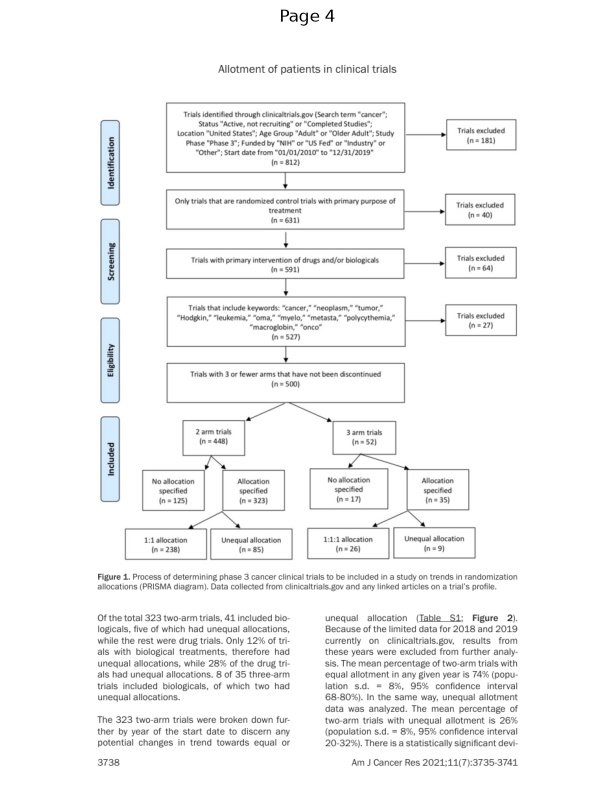

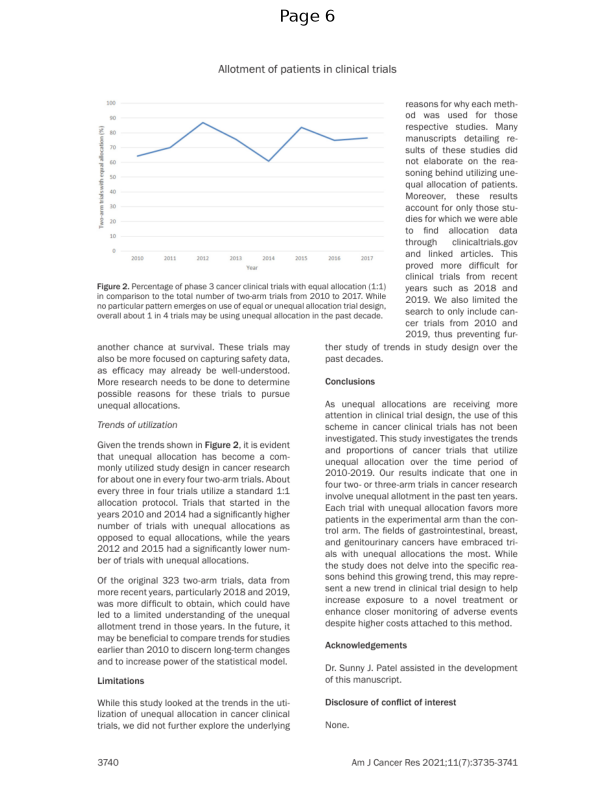

In [31]:
import matplotlib.pyplot as plt
from PIL import Image
import io

for page_num in [3, 5]:
    page = doc[page_num]

    pix = page.get_pixmap(
        matrix=fitz.Matrix(1.5, 1.5),
        alpha=False
    )

    img = Image.open(io.BytesIO(pix.tobytes("png")))

    plt.figure(figsize=(12, 10))
    plt.imshow(img)
    plt.title(f"Page {page_num + 1}")
    plt.axis("off")
    plt.show()

In [32]:
page = doc[5]

blocks = page.get_text("blocks")

for i, block in enumerate(blocks):
    x0, y0, x1, y1, text, *_ = block

    print(f"\nBlock {i}")
    print(f"Position: ({x0:.1f}, {y0:.1f}, {x1:.1f}, {y1:.1f})")
    print(text[:500])
    print("-" * 60)


Block 0
Position: (214.3, 32.4, 397.7, 47.8)
Allotment of patients in clinical trials

------------------------------------------------------------

Block 1
Position: (90.0, 747.4, 522.3, 760.2)
3740	
Am J Cancer Res 2021;11(7):3735-3741

------------------------------------------------------------

Block 2
Position: (89.9, 320.0, 290.4, 392.3)
another chance at survival. These trials may 
also be more focused on capturing safety data, 
as efficacy may already be well-understood. 
More research needs to be done to determine 
possible reasons for these trials to pursue 
unequal allocations. 

------------------------------------------------------------

Block 3
Position: (89.9, 399.8, 172.3, 412.7)
Trends of utilization

------------------------------------------------------------

Block 4
Position: (89.9, 420.3, 290.4, 552.1)
Given the trends shown in Figure 2, it is evident 
that unequal allocation has become a com­
monly utilized study design in cancer research 
for about one in eve

Image Format: jpeg
Image Size: (900, 535)


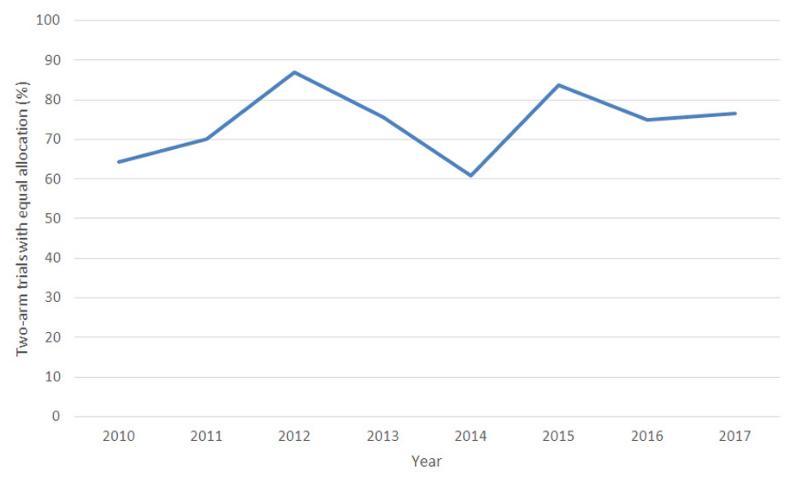

In [33]:
import io
from PIL import Image
import matplotlib.pyplot as plt

image_data = doc.extract_image(131)

image_bytes = image_data["image"]

img = Image.open(io.BytesIO(image_bytes))

print("Image Format:", image_data["ext"])
print("Image Size:", img.size)

plt.figure(figsize=(12, 6))
plt.imshow(img)
plt.axis("off")
plt.show()

In [34]:
import pdfplumber

pdf_path = r"D:\Projects\OncoLens-GenAI\data\raw\cancer-clinical-trials\Unequal allotment of patients in phase III oncology clinical trial.pdf"

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[5]

    text = page.extract_text()

    print("Extracted Text:")
    print(text)

    print("\n" + "=" * 60)
    print("Number of Images:", len(page.images))

    for i, img in enumerate(page.images):
        print(f"\nImage {i + 1}")
        print("Position:", img["x0"], img["top"], img["x1"], img["bottom"])
        print("Width:", img["width"])
        print("Height:", img["height"])

Extracted Text:
Allotment of patients in clinical trials
reasons for why each meth-
od was used for those
respective studies. Many
manuscripts detailing re-
sults of these studies did
not elaborate on the rea-
soning behind utilizing une-
qual allocation of patients.
Moreover, these results
account for only those stu-
dies for which we were able
to find allocation data
through clinicaltrials.gov
and linked articles. This
proved more difficult for
clinical trials from recent
Figure 2. Percentage of phase 3 cancer clinical trials with equal allocation (1:1) years such as 2018 and
in comparison to the total number of two-arm trials from 2010 to 2017. While
2019. We also limited the
no particular pattern emerges on use of equal or unequal allocation trial design,
search to only include can-
overall about 1 in 4 trials may be using unequal allocation in the past decade.
cer trials from 2010 and
2019, thus preventing fur-
another chance at survival. These trials may ther study of trends in s

In [35]:
from pypdf import PdfReader

pdf_path = r"D:\Projects\OncoLens-GenAI\data\raw\cancer-clinical-trials\Unequal allotment of patients in phase III oncology clinical trial.pdf"

reader = PdfReader(pdf_path)

page = reader.pages[5]

text = page.extract_text()

print("Extracted Text:")
print(text)

print("\n" + "=" * 60)
print("Page Resources:")
print(page.get("/Resources"))

Extracted Text:
Allotment of patients in clinical trials
3740 Am J Cancer Res 2021;11(7):3735-3741
another chance at survival. These trials may 
also be more focused on capturing safety data, 
as efficacy may already be well-understood. 
More research needs to be done to determine 
possible reasons for these trials to pursue 
unequal allocations. 
Trends of utilization
Given the trends shown in Figure 2, it is evident 
that unequal allocation has become a com -
monly utilized study design in cancer research 
for about one in every four two-arm trials. About 
every three in four trials utilize a standard 1:1 
allocation protocol. Trials that started in the 
years 2010 and 2014 had a significantly higher 
number of trials with unequal allocations as 
opposed to equal allocations, while the years 
2012 and 2015 had a significantly lower num-
ber of trials with unequal allocations. 
Of the original 323 two-arm trials, data from 
more recent years, particularly 2018 and 2019, 
was more diff

In [36]:
from unstructured.partition.pdf import partition_pdf

elements_test2 = partition_pdf(
    filename=pdf_path,
    strategy="hi_res"
)

page6_elements = [
    element for element in elements_test2
    if element.metadata.page_number == 6
]

for i, element in enumerate(page6_elements):
    print(f"\nElement {i}")
    print("Type:", type(element).__name__)
    print("Category:", element.category)
    print("Text:", str(element)[:500])
    print("Coordinates:", element.metadata.coordinates)
    print("-" * 60)


Element 0
Type: Title
Category: Title
Text: Allotment of patients in clinical trials
Coordinates: CoordinatesMetadata(points=((np.float64(594.43994140625), np.float64(96.59217834472656)), (np.float64(594.43994140625), np.float64(132.77444444444453)), (np.float64(1107.1827392578125), np.float64(132.77444444444453)), (np.float64(1107.1827392578125), np.float64(96.59217834472656))), system=<unstructured.documents.coordinates.PixelSpace object at 0x000001D49C7D9280>)
------------------------------------------------------------

Element 1
Type: Image
Category: Image
Text: 100 90 80 70 60 50 40 30 20 Two-arm trials with equal allocation (%) 2010 2011 2012 2013 2014 Year 2015 2016 2017
Coordinates: CoordinatesMetadata(points=((np.float64(249.6063233333333), np.float64(199.99983027777768)), (np.float64(249.6063233333333), np.float64(690.4165055555555)), (np.float64(1074.6063233333334), np.float64(690.4165055555555)), (np.float64(1074.6063233333334), np.float64(199.99983027777768))), system=<u

In [37]:
from unstructured.documents.elements import Table

for i, element in enumerate(elements_hi_res):
    if isinstance(element, Table):
        print(f"Table {i}")
        print("Text:")
        print(element.text)

        print("\nHTML:")
        print(element.metadata.text_as_html)

Table 289
Text:
Samples Group 1 Group 2 Both groups Concentration (lM) 5 2.5 Sensitivity (%) 100 46 71 60 Speciﬁcity (%) 75 88 83 95 PPV 80 79 83 93 NPV 100 61 73 71 AUC 0.88 0.65 0.78 NA 95 % CI 0.88–1 0.53–0.833 0.68–0.88 NA

HTML:
None


In [38]:
import fitz

pdf_path = next(BASE_DIR.rglob(
    "A c-MET-Targeted Topical Fluorescent Probe cMBP-ICG*.pdf"
))

doc = fitz.open(pdf_path)

page = doc[5]

tables = page.find_tables()

print("Detected Tables:", len(tables.tables))

for i, table in enumerate(tables.tables):
    print(f"\nTable {i + 1}")
    print(table.extract())

Detected Tables: 1

Table 1
[['Samples', 'Group1', 'Group2', 'Bothgroups', 'Surgeons'], ['Concentration(lM)', '5', '25\n.', '', ''], ['Sensitivity(%)', '100', '46', '71', '60'], ['Specificity(%)', '75', '88', '83', '95'], ['PPV', '80', '79', '83', '93'], ['NPV', '100', '61', '73', '71'], ['AUC', '088\n.', '065\n.', '078\n.', 'NA'], ['95%CI', '088 1\n. –', '053 0833\n. – .', '068 088\n. – .', 'NA']]


In [39]:
import pdfplumber

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[5]

    tables = page.extract_tables()

    print("Detected Tables:", len(tables))

    for i, table in enumerate(tables):
        print(f"\nTable {i + 1}")
        for row in table:
            print(row)

Detected Tables: 0


In [41]:
from pathlib import Path

second_pdf_path = next(
    BASE_DIR.rglob(
        "Unequal allotment of patients in phase III oncology clinical trial.pdf"
    )
)

print(second_pdf_path)

..\data\raw\cancer-clinical-trials\Unequal allotment of patients in phase III oncology clinical trial.pdf


In [42]:
import fitz

doc = fitz.open(second_pdf_path)
page = doc[5]

tables = page.find_tables()

print("Detected Tables:", len(tables.tables))

for i, table in enumerate(tables.tables):
    print(f"\nTable {i + 1}")
    print(table.extract())

Detected Tables: 0


In [44]:
page = doc[5]

images = page.get_images(full=True)

print("Embedded Images:", len(images))

for i, img in enumerate(images):
    xref = img[0]
    image_data = doc.extract_image(xref)

    print(
        f"Image {i + 1}:",
        image_data["width"],
        "x",
        image_data["height"],
        image_data["ext"]
    )

Embedded Images: 1
Image 1: 900 x 535 jpeg


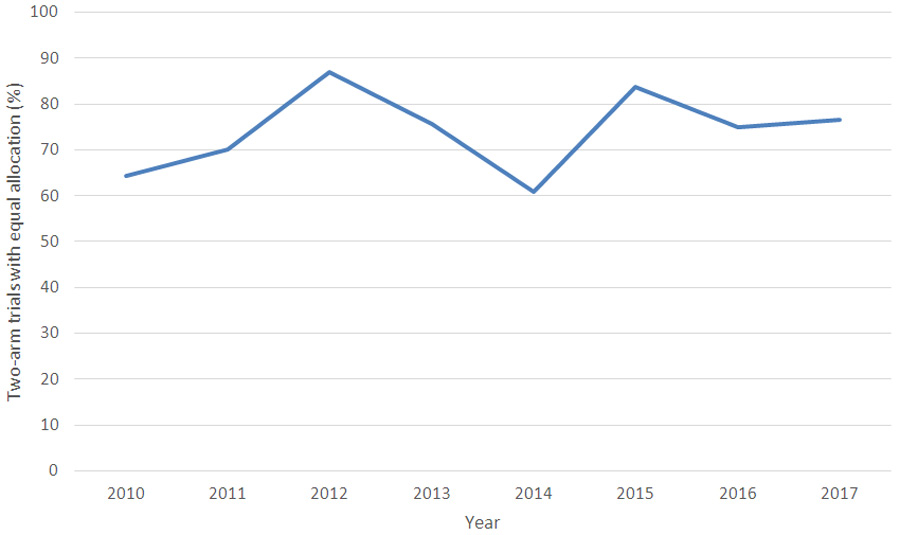

In [45]:
from PIL import Image
from io import BytesIO
from IPython.display import display

xref = page.get_images(full=True)[0][0]

image_data = doc.extract_image(xref)

chart = Image.open(
    BytesIO(image_data["image"])
)

display(chart)

# Document Processing — Evaluation & Final Decision

## 1. Evaluated Libraries

We evaluated four PDF processing libraries:

1. PyMuPDF
2. pdfplumber
3. PyPDF
4. Unstructured

The evaluation focused on:
- Native text extraction quality.
- Reading order and document layout.
- Metadata extraction.
- Table detection and extraction.
- Image and figure extraction.
- Figure caption detection.
- Handling multi-column scientific papers.

Processing speed was not considered a selection criterion.

## 2. Evaluation Results

### PyMuPDF
- Successfully extracted native PDF text.
- Provides detailed text blocks, spans, font information, and coordinates.
- Successfully detected and extracted a table in the first test document, although some cell values required correction.
- Successfully extracted embedded images from PDFs.
- Suitable for extracting native PDF content and preserving useful layout information.

### Unstructured
- `fast` strategy showed poor element classification in the tested scientific paper.
- `hi_res` successfully detected images, tables, and figure captions.
- Provided useful document element classification and layout information.
- Table extraction returned flattened text without HTML structure in our test.
- OCR of chart labels was not consistently reliable.

### pdfplumber
- Provided character-level and word-level extraction with coordinates.
- Reading order was problematic in multi-column documents.
- Failed to detect the tested table using default extraction settings.

### PyPDF
- Successfully extracted native text and metadata.
- Reading order and visual structure were not sufficiently reliable for our requirements.
- Did not provide a clear advantage over PyMuPDF in our experiments.

## 3. Final Technology Selection

We will use a hybrid approach:

**PyMuPDF — Primary PDF Processing**
- Native text extraction.
- Page and block inspection.
- Coordinates and layout information.
- Table detection and extraction.
- Embedded image extraction.

**Unstructured (Hi-Res) — Supplementary Layout Processing**
- Document element classification.
- Figure caption detection.
- Additional image and table detection.
- Supplementary layout information.

Important: Unstructured OCR output and extracted table values must be validated before being used as reliable source data.

## 4. Removed Libraries

The following libraries will not be used in the current Document Processing implementation:
- pdfplumber
- PyPDF

## 5. Final Decision

The selected combination is:

**PyMuPDF + Unstructured (Hi-Res)**

This combination provides native text extraction, layout information, table and image extraction, and supplementary document element detection.

The next phase is Chunking. We will begin it only after completing the Document Processing evaluation and implementation.
